# MI Part 2: Classification Pipeline (the high-cost flag)
**Provider Network Access and Cost Planner** · David Satizabal · CAI4510C Machine Intelligence

**Question:** will this member be **high-cost** next quarter? Yes or no.

MI Part 1 predicted a dollar amount. The AI Part 1 planner just needs a flag, "is this a heavy patient?", so it can spread heavy patients across doctors and place the sickest members first. **High-cost = the top 10% of next-quarter cost**, with the dollar line set from the training months only.

Same data as MI Part 1: 1,500 synthetic members, monthly from January 2025 to September 2026 (seed 42).

**To run in Colab:** run the first cell. If the files are missing, it clones the class repo, or asks you to upload `MI_Part2_Classification.zip`.

In [1]:
# Find the project folder. If it's missing: clone the class repo, and if that fails, ask for the zip
import sys, os, zipfile, subprocess
from pathlib import Path

FOLDER = "MI_Part2_Classification"
CANDIDATES = [Path.cwd(), Path.cwd() / FOLDER, Path("/content") / FOLDER,
              Path("/content/Artificial-Intelligence-Class") / FOLDER]
find = lambda: next((p for p in CANDIDATES if (p / "src" / "run_mi_part2.py").exists()), None)
PROJECT = find()

if PROJECT is None and Path("/content").exists():
    subprocess.run(["git", "clone", "-q", "-b", "finalProject", "https://github.com/DASatizabal/Artificial-Intelligence-Class",
                    "/content/Artificial-Intelligence-Class"])
    PROJECT = find()

if PROJECT is None:
    try:
        from google.colab import files
        print(f"Project folder not found. Upload {FOLDER}.zip")
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content")
        PROJECT = find()
    except ImportError:
        raise FileNotFoundError(f"Put this notebook inside the {FOLDER} folder, or run it in Colab.")

os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT / "src"))
print("Project folder:", PROJECT.name)

Project folder: MI_Part2_Classification


This cell finds the project files. In Colab it clones the class repo (finalProject branch), and if that fails it asks for a zip upload, so nothing crashes.

31,563 rows | 1500 members | 2025-01 to 2026-09
miles to PCP: mean 2.70 before, 3.10 after Pinecrest leaves; 170 members farther


cutoff $3,904 | train 13,500 (0.100 high) | test 3,000 (0.102 high)
                          model  accuracy_mean  precision_mean  recall_mean  f1_mean  roc_auc_mean  pr_auc_mean  recall_sd  roc_auc_sd
Majority baseline (always 'no')         0.9000          0.0000       0.0000   0.0000        0.5000       0.1000     0.0000      0.0000
            Logistic regression         0.9019          0.5677       0.0785   0.1363        0.7610       0.3096     0.0299      0.0150
  Logistic regression, balanced         0.7019          0.1994       0.6547   0.3054        0.7600       0.3087     0.0496      0.0138
        Decision tree, balanced         0.6622          0.1826       0.6742   0.2865        0.7214       0.2389     0.0495      0.0211
                          model  accuracy  precision  recall     f1  roc_auc  pr_auc
Majority baseline (always 'no')    0.8983     0.0000  0.0000 0.0000   0.5000  0.1017
            Logistic regression    0.9027     0.7241  0.0689 0.1257   0.7528  0.3366
  

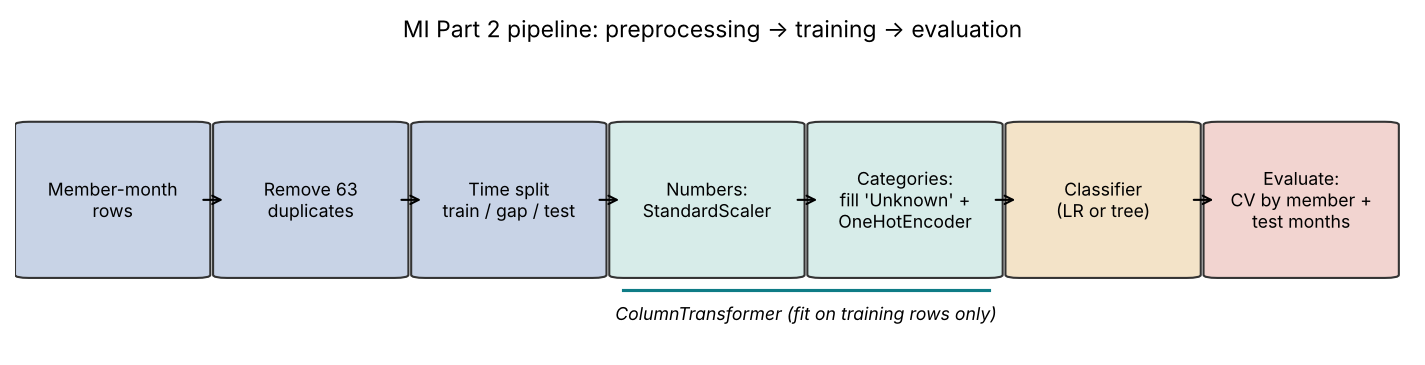

In [2]:
import pandas as pd, json
from IPython.display import Image
import gen_claims, run_mi_part2
gen_claims.main()        # same seeded data as MI Part 1
run_mi_part2.main()
m = json.load(open("outputs/metrics.json"))
print(f"High-cost line: ${m['high_cost_cutoff_dollars']:,.0f} next quarter | train {m['train_rows']:,} rows | test {m['test_rows']:,} rows")
Image("outputs/pipeline_diagram.png")

**The evaluation plan:**
- **Split:** train on January to September 2025 and test on January to February 2026, with the same 3-month gap as MI Part 1, so no answer leaks into the test months.
- **The high-cost line:** next-quarter cost of **\$3,904 or more**. About 10% of rows are "yes".
- **Cross-validation:** 5 folds, each with the same 10% "yes" mix (stratified). **Every member stays in one fold** (grouped by member). Otherwise the model could train on a member's March row and get graded on their April row, which is almost the same row, and the scores would look better than they really are.
- **Metrics:** accuracy, precision, recall, F1, ROC-AUC and PR-AUC. **Recall matters most**: missing a member who becomes high-cost costs more than an extra outreach call.
- **The pipeline:** a ColumnTransformer scales the numbers and turns categories into 0/1 columns, filling missing plan types with "Unknown". It is fit on training rows only.

In [3]:
cv = pd.DataFrame(m["cv"])[["model", "accuracy_mean", "precision_mean", "recall_mean", "recall_sd", "f1_mean", "roc_auc_mean", "pr_auc_mean"]]
display(cv)

,model,accuracy_mean,precision_mean,recall_mean,recall_sd,f1_mean,roc_auc_mean,pr_auc_mean
0,Majority baseline (always 'no'),0.9000,0.0000,0.0000,0.0000,0.0000,0.5000,0.1000
1,Logistic regression,0.9019,0.5677,0.0785,0.0299,0.1363,0.7610,0.3096
2,"Logistic regression, balanced",0.7019,0.1994,0.6547,0.0496,0.3054,0.7600,0.3087
3,"Decision tree, balanced",0.6622,0.1826,0.6742,0.0495,0.2865,0.7214,0.2389


**Cross-validation on the training months (average of 5 folds):**
- The **"always say no" baseline** is 90% accurate and catches **zero** high-cost members. That's the accuracy trap.
- **Plain logistic regression** is 90.2% accurate but only catches 7.9% of high-cost members. Because "no" is 9 times more common, the model learned that "no" is usually safe.
- **Balanced weighting** makes each missed high-cost member count about 9 times more during training. Recall jumps to 65.5% (give or take 5 points across folds), while the ranking skill (ROC-AUC 0.760) stays the same. The model didn't get smarter. It just stopped being afraid to say yes.

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Majority baseline (always 'no'),0.8983,0.0000,0.0000,0.0000,0.5000,0.1017
1,Logistic regression,0.9027,0.7241,0.0689,0.1257,0.7528,0.3366
2,"Logistic regression, balanced",0.7047,0.2063,0.6689,0.3153,0.7523,0.3372
3,"Decision tree, balanced",0.6207,0.1728,0.7213,0.2788,0.7124,0.2562


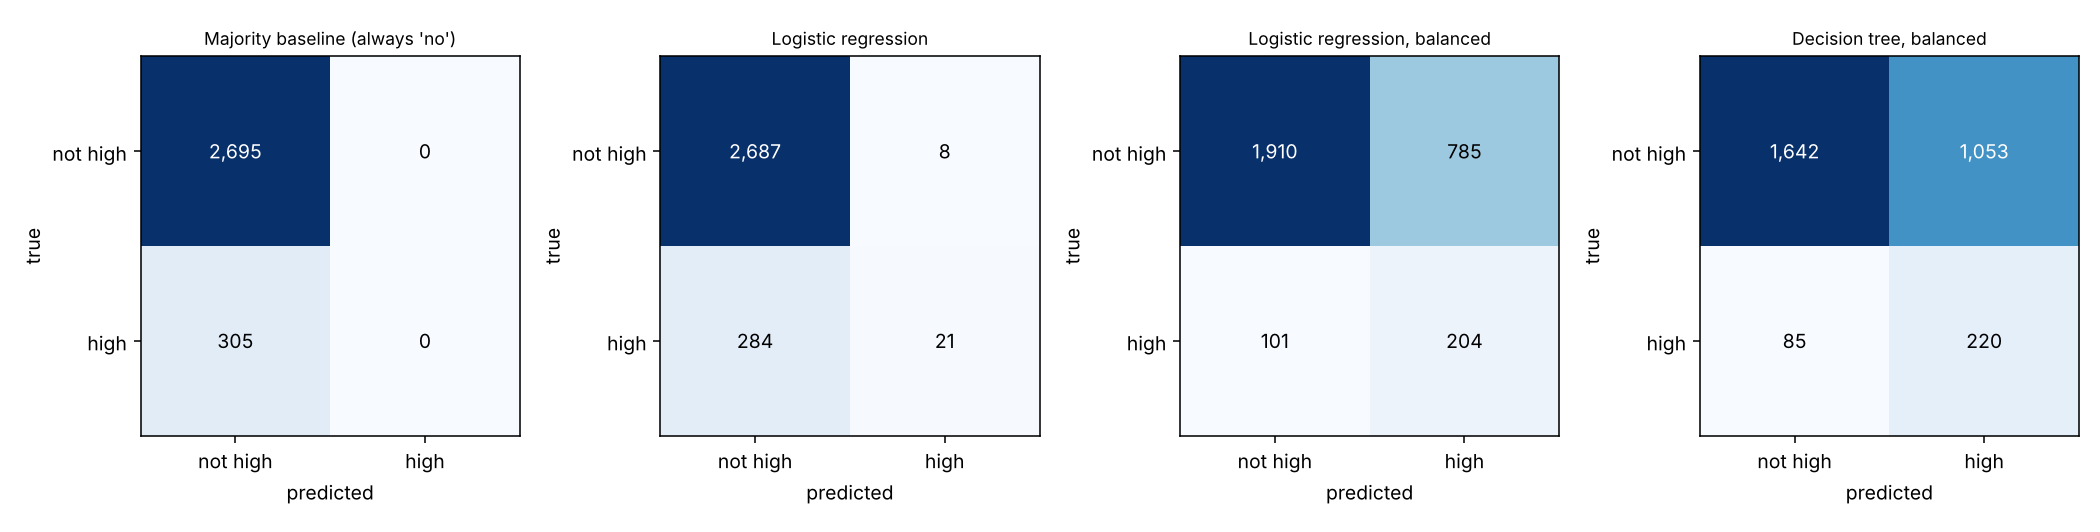

In [4]:
test = pd.DataFrame(m["test"]); display(test)
Image("outputs/confusion_matrices.png")

**On the test months (3,000 rows, 305 truly high-cost):**

| Model | Caught | Missed | False alarms | Recall | Precision |
|---|---|---|---|---|---|
| Always "no" | 0 | 305 | 0 | 0% | n/a |
| Logistic regression | 21 | 284 | 8 | 6.9% | 72.4% |
| **Logistic regression, balanced** | **204** | **101** | **785** | **66.9%** | **20.6%** |
| Decision tree, balanced | 220 | 85 | 1,053 | 72.1% | 17.3% |

**Champion: balanced logistic regression.** The tree catches 16 more members but raises 268 more false alarms. Its ranking quality is also lower (ROC-AUC 0.712 vs 0.752, PR-AUC 0.256 vs 0.337). Logistic regression is the simpler, more honest model here, which is the same lesson as the midterm.

**Precision of 20.6% means about 1 in 5 flagged members really becomes high-cost.** For outreach, that can still pay off: a \$250 call that prevents part of a \$3,900+ quarter. The exact cut-off should come from costs, not from 0.5, and that's done in the capstone.

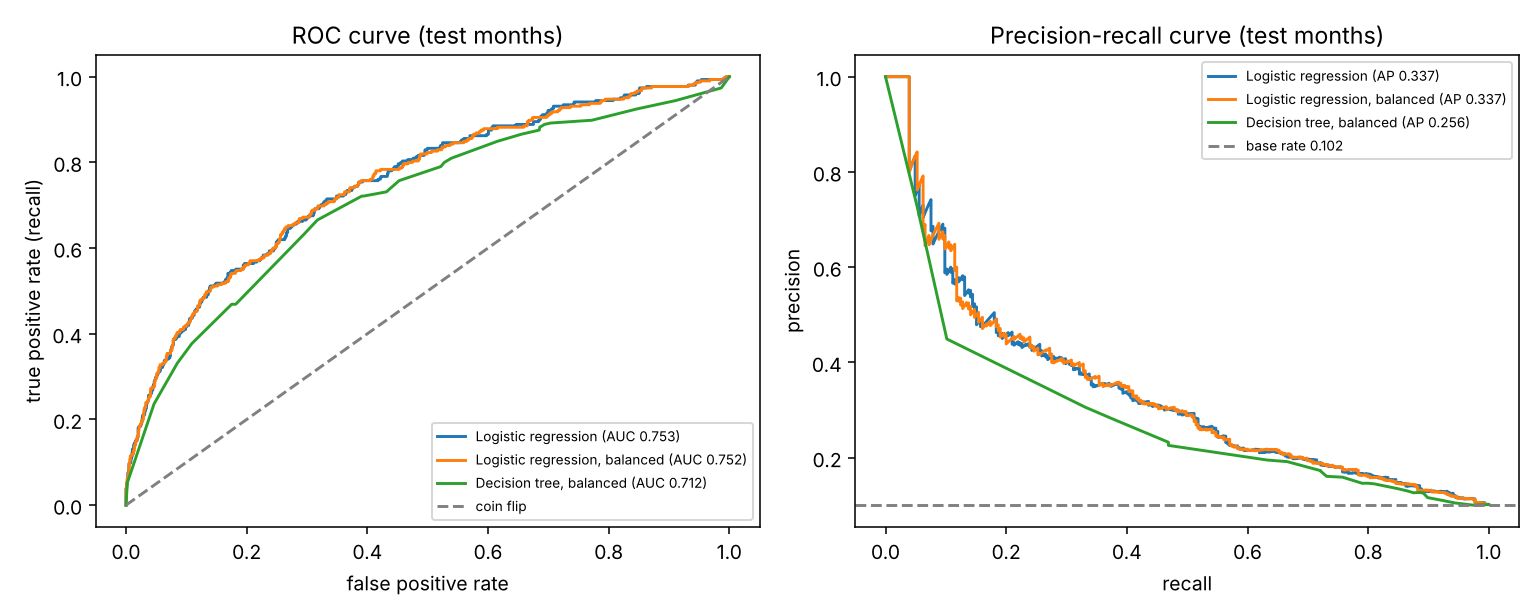

In [5]:
Image("outputs/roc_pr_curves.png")

- **ROC curve:** how well each model ranks a high-cost member above a normal one. The diagonal is a coin flip. Both logistic models sit at 0.75.
- **Precision-recall curve:** the more honest view when "yes" is rare. A random guess sits at the 10% base rate, and logistic regression reaches about 3 times that on average (PR-AUC 0.337).

In [6]:
print("Balanced logistic regression, biggest effects (per 1 standard deviation):")
print(pd.Series(m["lr_balanced_coefficients"]).to_string())
print("\nDecision tree, feature importance:")
print(pd.Series(m["tree_importances"]).to_string())
flags = pd.read_csv("outputs/predicted_high_cost_flags.csv"); display(flags.head(8))
print(m["flags_for_ai_planner"])

Balanced logistic regression, biggest effects (per 1 standard deviation):
age                      0.628
plan_type_Unknown       -0.487
chronic_conditions       0.361
cost_prior_12m           0.324
plan_type_Marketplace    0.299
saw_pcp_last_3m         -0.195
sex_F                   -0.191
county_Broward          -0.154
admits_12m              -0.126
er_visits_6m             0.115

Decision tree, feature importance:
age                      0.578
cost_prior_12m           0.244
chronic_conditions       0.074
cost_prior_3m            0.025
cost_month               0.021
plan_type_Marketplace    0.017
county_Miami-Dade        0.011
miles_to_pcp             0.010


,member_id,month,p_high_cost,rank,high_cost_flag
0,M0231,2026-02,0.9875,1,1
1,M0219,2026-02,0.9426,2,1
2,M0063,2026-02,0.9409,3,1
3,M0266,2026-02,0.9397,4,1
4,M0057,2026-02,0.9390,5,1
5,M0311,2026-02,0.9281,6,1
6,M0322,2026-02,0.9268,7,1
7,M0314,2026-02,0.9166,8,1


{'members': 600, 'flagged': 60, 'would_be_flagged_at_0.5': 195}


**What drives the flag:** age, chronic conditions and last year's cost push risk up in both models. Seeing a PCP in the last 3 months pushes it down, the same access link we saw in MI Part 1.

**Hand-off to the AI planner.** The file `predicted_high_cost_flags.csv` scores the 600 AI Part 1 members on their latest test month. At the 0.5 line, 195 of them (33%) would be flagged, which is far too many for the planner's per-doctor cap of 35% of open slots. So the hand-off flags the **riskiest 60 (10%) by predicted probability**. This file is ready to replace the placeholder flag in AI Part 1. The planner does not read it yet; wiring it in is the next integration step.

**Summary.** The "always no" baseline is 90% accurate and useless. Balanced logistic regression catches 66.9% of next quarter's high-cost members with the best balance of recall and false alarms. It beats a decision tree on ranking quality and produces the high-cost list the planner needs.